## Setup: install libraries

In [1]:
# Install PyPDF2 to read PDFs, spaCy and NLTK for the NLP operations
!pip install PyPDF2 spacy nltk

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 232.6/232.6 kB 11.2 MB/s eta 0:00:00


In [2]:
# Download spaCy's small English model
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 54.0 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


## Question 1: Working with PDF: Reading
**(a)** Open the PDF, print the number of pages and the text of the first page.
**(b)** Print the text of every page with its page number.
**(c)** Print only the third page (index 2).
**(d)** Find the pages on which the word **attention** appears.
**(e)** Count the words of the PDF page by page.

In [3]:
# (a) Open the PDF, print the number of pages and the text of the first page
from PyPDF2 import PdfReader
reader=PdfReader('transformers_for_nlp.pdf')
print('Number of pages: ',len(reader.pages))

page=reader.pages[0]
text=page.extract_text()

print(text)

Number of pages:  3
Transformers for NLP  |  Page 1
 Transformers for NLP
 A practical guide: architecture, model families, and hands-on NLP operations
 
1. What is a Transformer?
The Transformer, introduced in Attention Is All You Need (Vaswani et al., 2017), is a neural architecture that
processes entire sequences in parallel using self-attention instead of the step-by-step recurrence used by
RNNs and LSTMs. This makes training far faster on modern hardware and lets the model capture long-range
dependencies between words. Almost every state-of-the-art NLP system today (BERT, GPT, T5, LLaMA,
Claude) is built on this idea.
2. Core Components
Tokenization and embeddings: text is split into subword tokens (BPE, WordPiece) and each token is
mapped to a dense vector.
Positional encoding: since attention has no sense of order, position information is added to the
embeddings.
Self-attention: every token compares itself with every other token to decide which ones matter for its
meaning.
M

In [4]:
# (b) Loop through every page and print its text with the page number
from PyPDF2 import PdfReader

reader=PdfReader('transformers_for_nlp.pdf')

for page_number,page in enumerate(reader.pages,start=1):
  print(f'\n--- Page{page_number} ---')
  text=page.extract_text()
  print(text)


--- Page1 ---
Transformers for NLP  |  Page 1
 Transformers for NLP
 A practical guide: architecture, model families, and hands-on NLP operations
 
1. What is a Transformer?
The Transformer, introduced in Attention Is All You Need (Vaswani et al., 2017), is a neural architecture that
processes entire sequences in parallel using self-attention instead of the step-by-step recurrence used by
RNNs and LSTMs. This makes training far faster on modern hardware and lets the model capture long-range
dependencies between words. Almost every state-of-the-art NLP system today (BERT, GPT, T5, LLaMA,
Claude) is built on this idea.
2. Core Components
Tokenization and embeddings: text is split into subword tokens (BPE, WordPiece) and each token is
mapped to a dense vector.
Positional encoding: since attention has no sense of order, position information is added to the
embeddings.
Self-attention: every token compares itself with every other token to decide which ones matter for its
meaning.
Multi-

In [5]:
# (c) Read only the third page using index 2
from PyPDF2 import PdfReader
reader=PdfReader('transformers_for_nlp.pdf')
page=reader.pages[2]
print(page.extract_text())

Transformers for NLP  |  Page 3
def metrics(p):
    return acc.compute(predictions=np.argmax(p.predictions, axis=-1), references=p.label_ids)
args = TrainingArguments(output_dir="out", num_train_epochs=2, learning_rate=2e-5,
                         per_device_train_batch_size=16, eval_strategy="epoch")
trainer = Trainer(model=model, args=args, compute_metrics=metrics,
                  train_dataset=enc["train"].shuffle(seed=1).select(range(4000)),
                  eval_dataset=enc["test"].shuffle(seed=1).select(range(1000)))
trainer.train()
trainer.save_model("my-sentiment-model")
7. Practical Tips
Pick the right architecture: encoder models for understanding tasks, decoder or encoder-decoder models
for generation.
Start small: DistilBERT or MiniLM models train quickly and are often accurate enough; scale up only if
needed.
Mind the context window: most BERT-style models accept 512 tokens; chunk longer documents.
Use a GPU: fine-tuning on CPU is slow. Google Colab offers free GP

In [6]:
# (d) Check every page for the search word and print the page numbers where it is found
reader=PdfReader('transformers_for_nlp.pdf')
search_word='attention'
for page_number,page in enumerate(reader.pages,start=1):
  text=page.extract_text()
  if search_word.lower() in text.lower():
    print(f"' {search_word}' found on page {page_number}")

' attention' found on page 1
' attention' found on page 3


In [7]:
# (e) Add the words of each page to a running total (the total after every page is printed)
reader=PdfReader('transformers_for_nlp.pdf')
word_count=0
for page in reader.pages:
  text=page.extract_text()
  if text:
    word_count+=len(text.split())

  print('Total words:',word_count)

Total words: 370
Total words: 638
Total words: 793


## Question 2: Working with PDF: Writing and Extracting
**(a)** Copy the first page of the PDF into a new file `first_page.pdf`.
**(b)** Read the text of the first three pages (index 0, 1 and 2) of the PDF one by one, and join them into a single Python string called pdf_text
**(c)** Print the first 300 characters of that text.


In [8]:
# (a) Add the first page to a PdfWriter and save it as first_page.pdf
from PyPDF2 import PdfReader,PdfWriter
reader=PdfReader("transformers_for_nlp.pdf")
writer=PdfWriter()
writer.add_page(reader.pages[0])
with open('first_page.pdf','wb') as output:
  writer.write(output)
print('First page copied successfully!')

First page copied successfully!


In [9]:
# (b) Read the text of first three pages
reader=PdfReader('transformers_for_nlp.pdf')

page=reader.pages[0]
text1=page.extract_text()

page=reader.pages[1]
text2=page.extract_text()

page=reader.pages[2]
text3=page.extract_text()

pdf_text=text1+text2+text3

In [10]:
# (c) Print the first 300 characters of the extracted text
print(pdf_text[:300])

Transformers for NLP  |  Page 1
 Transformers for NLP
 A practical guide: architecture, model families, and hands-on NLP operations
 
1. What is a Transformer?
The Transformer, introduced in Attention Is All You Need (Vaswani et al., 2017), is a neural architecture that
processes entire sequences in


## Question 3: Tokenization: Basics
**(a)** Load spaCy, create the `doc` from the text of the PDF and print the tokens of `doc[87:108]`.
**(b)** Print the index of each token of `doc[87:108]`.
**(c)** For the same tokens print whether they are alphabetic, punctuation or space.
**(d)** Remove the punctuation from the tokens of `doc[108:138]`.
**(e)** Print only the alphabetic tokens of `doc[108:138]`.


In [11]:
# (a) Load the English model, create a Doc from the PDF text and print the tokens of doc[87:108]
import spacy
from PyPDF2 import PdfReader
nlp=spacy.load('en_core_web_sm')

reader=PdfReader('transformers_for_nlp.pdf')

page=reader.pages[0]
text1=page.extract_text()

page=reader.pages[1]
text2=page.extract_text()

page=reader.pages[2]
text3=page.extract_text()

doc=nlp(pdf_text)

for token in doc[87:108]:
  print(token.text)

This
makes
training
far
faster
on
modern
hardware
and
lets
the
model
capture
long
-
range


dependencies
between
words
.


In [12]:
# (b) token.i gives the index (position) of each token
for token in doc[87:108]:
  print(token.i,token.text)

87 This
88 makes
89 training
90 far
91 faster
92 on
93 modern
94 hardware
95 and
96 lets
97 the
98 model
99 capture
100 long
101 -
102 range
103 

104 dependencies
105 between
106 words
107 .


In [13]:
# (c) attributes,alpha=alphabetic,punct=punctuation,space=whitespace
for token in doc[87:108]:
  print(
      token.text,
      token.is_alpha,
      token.is_punct,
      token.is_space )

This True False False
makes True False False
training True False False
far True False False
faster True False False
on True False False
modern True False False
hardware True False False
and True False False
lets True False False
the True False False
model True False False
capture True False False
long True False False
- False True False
range True False False

 False False True
dependencies True False False
between True False False
words True False False
. False True False


In [14]:
# (d) removing punctuation after tokenization
for token in doc[108:138]:
  if not token.is_punct:
    print(token.text)

Almost
every
state
of
the
art
NLP
system
today
BERT
GPT
T5
LLaMA


Claude
is
built
on
this
idea


In [15]:
# (e) keep only the alphabetic tokens
for token in doc[108:138]:
  if token.is_alpha:
    print(token.text)

Almost
every
state
of
the
art
NLP
system
today
BERT
GPT
LLaMA
Claude
is
built
on
this
idea


## Question 4: Tokenization: Lists, Sentences and Special Cases
**(a)** Store the tokens of `doc[171:191]` in a Python list and print it.
**(b)** Split the text of `doc[87:138]` into sentences and print the tokens of each sentence.
**(c)** Print a table with `is_alpha`, `like_num` and `is_punct` for the tokens of `doc[37:87]` (the sentence with the year 2017).


In [16]:
# (a) Put the token texts into a list with a list comprehension
tokens= [token.text for token in doc[171:191]]
print(tokens)

['\x7fPositional', 'encoding', ':', 'since', 'attention', 'has', 'no', 'sense', 'of', 'order', ',', 'position', 'information', 'is', 'added', 'to', 'the', '\n', 'embeddings', '.']


In [17]:
# (b) Take the text of tokens 93 to 144, split it into sentences with doc.sents and print the tokens of each
sample_text=doc[87:138].text
sample_doc=nlp(sample_text)
for sentence in sample_doc.sents:
  print('Sentence:',sentence.text)
  for token in sentence:
   print(token.text)


print()

Sentence: This makes training far faster on modern hardware and lets the model capture long-range
dependencies between words.
This
makes
training
far
faster
on
modern
hardware
and
lets
the
model
capture
long
-
range


dependencies
between
words
.
Sentence: Almost every state-of-the-art NLP system today (BERT, GPT, T5, LLaMA,
Claude) is built on this idea.
Almost
every
state
-
of
-
the
-
art
NLP
system
today
(
BERT
,
GPT
,
T5
,
LLaMA
,


Claude
)
is
built
on
this
idea
.



In [18]:
# (c) Print a table showing alphabetic, number-like and punctuation tokens
print('Token\tAlpha\tNumber\tPunctuation')
for token in doc[37:87]:
  print(token.text,"\t",token.is_alpha,"\t",token.like_num,"\t",token.is_punct)

Token	Alpha	Number	Punctuation
The 	 True 	 False 	 False
Transformer 	 True 	 False 	 False
, 	 False 	 False 	 True
introduced 	 True 	 False 	 False
in 	 True 	 False 	 False
Attention 	 True 	 False 	 False
Is 	 True 	 False 	 False
All 	 True 	 False 	 False
You 	 True 	 False 	 False
Need 	 True 	 False 	 False
( 	 False 	 False 	 True
Vaswani 	 True 	 False 	 False
et 	 True 	 False 	 False
al 	 True 	 False 	 False
. 	 False 	 False 	 True
, 	 False 	 False 	 True
2017 	 False 	 True 	 False
) 	 False 	 False 	 True
, 	 False 	 False 	 True
is 	 True 	 False 	 False
a 	 True 	 False 	 False
neural 	 True 	 False 	 False
architecture 	 True 	 False 	 False
that 	 True 	 False 	 False

 	 False 	 False 	 False
processes 	 True 	 False 	 False
entire 	 True 	 False 	 False
sequences 	 True 	 False 	 False
in 	 True 	 False 	 False
parallel 	 True 	 False 	 False
using 	 True 	 False 	 False
self 	 True 	 False 	 False
- 	 False 	 False 	 True
attention 	 True 	 False 	 False
inste

## Question 5: Stop Words Removal
**(a)** Check `is_stop` for every token of `doc[87:108]`.
**(b)** Collect the stop words of `doc[108:138]` in a list.
**(c)** Remove stop words and punctuation from `doc[192:214]` and print the remaining words.
**(d)** Remove stop words and punctuation from `doc[243:267]`, convert the words to lower case and join them.
**(e)** Display the number of stop words in spaCy's list and in NLTK's list.
**(f)** Create a function `remove_stopwords` and apply it to `doc[1338:1359]` .

In [20]:
# (a) token.is_stop is True when the token is a stop word
for token in doc[87:108]:
    print(token.text,"->",token.is_stop)

This -> True
makes -> False
training -> False
far -> False
faster -> False
on -> True
modern -> False
hardware -> False
and -> True
lets -> False
the -> True
model -> False
capture -> False
long -> False
- -> False
range -> False

 -> False
dependencies -> False
between -> True
words -> False
. -> False


In [21]:
# (b) Append every stop word of the span to a list
stopwords=[]


for token in doc[108:138]:
  if token.is_stop:
    stopwords.append(token.text)

print(stopwords)

['Almost', 'every', 'of', 'the', 'is', 'on', 'this']


In [22]:
# (c) Keep tokens that are neither stop words nor punctuation
words=[]


for token in doc[192:214]:
  if not token.is_stop and not token.is_punct:
    words.append(token.text)

print(words)

['\x7fSelf', 'attention', 'token', 'compares', 'token', 'decide', 'ones', 'matter', '\n', 'meaning']


In [23]:
# (d) Remove stop words and punctuation, convert to lower case and join the words
result=[]


for token in doc[243:267]:
  if not token.is_stop and not token.is_punct:
    result.append(token.text.lower())

print(" ".join(result))

feed forward network residual connections layernorm applied attention layer add 
 capacity stabilise training


In [24]:
# (e) Display spacy's stopword list size and NLTK's stopword list size
print(len(nlp.Defaults.stop_words))

import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
stop_words=set(stopwords.words('english'))
print(len(stop_words))

326
198


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [25]:
# (f) Function that removes stop words and punctuation from any text
def remove_stopwords(text):
    doc = nlp(text)
    result = []

    for token in doc:
        if not token.is_stop and not token.is_punct:
            result.append(token.text)

    return " ".join(result)


sentence_text = doc[1338:1359].text

print(remove_stopwords(sentence_text))

Consider bias safety pretrained models inherit biases training data test 
 population


## Question 6: Lemmatization (spaCy and NLTK)
**(a)** Print each token of `doc[87:108]` with its lemma.
**(b)** Lemmatize `doc[215:242]` and print it as one sentence.
**(c)** Print the POS and lemma of every token of `doc[171:191]`.
**(d)** Print the lemmas of `doc[108:138]` after removing stop words and punctuation.
**(e)** Create a function `lemmatize_text` and apply it to `doc[1253:1275]` .
**(f)** Use NLTK's `WordNetLemmatizer` on the words of `doc[87:108]`.
**(g)** Lemmatize the words of `doc[1338:1359]` as verbs using `pos='v'`.

In [26]:
# (a) token.lemma_ gives the base form of each word
for token in doc[87:108]:
  print(token.text, "->", token.lemma_)

This -> this
makes -> make
training -> training
far -> far
faster -> fast
on -> on
modern -> modern
hardware -> hardware
and -> and
lets -> let
the -> the
model -> model
capture -> capture
long -> long
- -> -
range -> range

 -> 

dependencies -> dependency
between -> between
words -> word
. -> .


In [27]:
# (b) Join the lemmas of the span into a lemmatized sentence
lemmatized_text=" ".join(token.lemma_ for token in doc[215:242])
print(lemmatized_text)

multi - head attention : several attention head run in parallel , each learn a different relationship ( syntax , 
 coreference , etc . ) .


In [28]:
# (c) Print the word with its POS tag and its lemma
for token in doc[171:191]:
  print(token.text,
        "POS:",token.pos_,
        "Lemma:",token.lemma_)

Positional POS: ADJ Lemma: positional
encoding POS: NOUN Lemma: encoding
: POS: PUNCT Lemma: :
since POS: SCONJ Lemma: since
attention POS: NOUN Lemma: attention
has POS: VERB Lemma: have
no POS: DET Lemma: no
sense POS: NOUN Lemma: sense
of POS: ADP Lemma: of
order POS: NOUN Lemma: order
, POS: PUNCT Lemma: ,
position POS: NOUN Lemma: position
information POS: NOUN Lemma: information
is POS: AUX Lemma: be
added POS: VERB Lemma: add
to POS: ADP Lemma: to
the POS: DET Lemma: the

 POS: SPACE Lemma: 

embeddings POS: NOUN Lemma: embedding
. POS: PUNCT Lemma: .


In [29]:
# (d) Collect lemmas of the words that are not stop words and not punctuation
words=[]
for token in doc[108:138]:
  if not token.is_stop and not token.is_punct:
    words.append(token.lemma_)

print(words)

['state', 'art', 'NLP', 'system', 'today', 'BERT', 'GPT', 'T5', 'LLaMA', '\n', 'Claude', 'build', 'idea']


In [30]:
# (e) Function that returns the lemmas of a text without stop words and punctuation
def lemmatize_text(text):
  doc=nlp(text)
  result=[]
  for token in doc:
    if not token.is_stop and not token.is_punct:
      result.append(token.lemma_)

  return " ".join(result)


sentence_text=doc[1253:1275].text

result=lemmatize_text(sentence_text)
print(result)

Start small distilbert MiniLM model train quickly accurate scale 
 need


In [31]:
# (f) lemmatization using nltk: download WordNet and create the lemmatizer
import nltk
nltk.download('wordnet')
nltk.download('omw-1.4')

from nltk.stem import WordNetLemmatizer
lemmatizer=WordNetLemmatizer()

words=doc[87:108].text.split()
for word in words:
    print(word,"->",lemmatizer.lemmatize(word))

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


This -> This
makes -> make
training -> training
far -> far
faster -> faster
on -> on
modern -> modern
hardware -> hardware
and -> and
lets -> let
the -> the
model -> model
capture -> capture
long-range -> long-range
dependencies -> dependency
between -> between
words. -> words.


In [32]:
# (g) pos='v' tells the lemmatizer to treat every word as a verb
words=doc[1338:1359].text.split()
for word in words:
    print(word,"->",lemmatizer.lemmatize(word,pos='v'))

Consider -> Consider
bias -> bias
and -> and
safety: -> safety:
pretrained -> pretrained
models -> model
inherit -> inherit
biases -> bias
from -> from
their -> their
training -> train
data; -> data;
test -> test
on -> on
your -> your
own -> own
population. -> population.


## Question 7: POS Tagging with spaCy
**(a)** Print each token of `doc[87:108]` with its POS tag.
**(b)** Print the POS tag and its meaning for the tokens of `doc[171:191]`.
**(c)** Print the adjectives of `doc[37:87]`.
**(d)** Print the adverbs of `doc[87:108]`.
**(e)** Print the proper nouns of `doc[108:138]`.
**(f)** Print the POS tag (`pos_`) and detailed tag (`tag_`) of `doc[192:214]`.

In [33]:
# (a) token.pos_ gives the part of speech of every token
for token in doc[87:108]:
  print(token.text,token.pos_)

This PRON
makes VERB
training NOUN
far ADV
faster ADV
on ADP
modern ADJ
hardware NOUN
and CCONJ
lets VERB
the DET
model NOUN
capture VERB
long ADJ
- PUNCT
range NOUN

 SPACE
dependencies NOUN
between ADP
words NOUN
. PUNCT


In [34]:
# (b) spacy.explain gives the meaning of a POS tag
for token in doc[171:191]:
  print(token.text,token.pos_,spacy.explain(token.pos_))

Positional ADJ adjective
encoding NOUN noun
: PUNCT punctuation
since SCONJ subordinating conjunction
attention NOUN noun
has VERB verb
no DET determiner
sense NOUN noun
of ADP adposition
order NOUN noun
, PUNCT punctuation
position NOUN noun
information NOUN noun
is AUX auxiliary
added VERB verb
to ADP adposition
the DET determiner

 SPACE space
embeddings NOUN noun
. PUNCT punctuation


In [35]:
# (c) Print only the adjectives
for token in doc[37:87]:
  if token.pos_ =='ADJ':
    print(token.text)

neural
entire


In [36]:
# (d) Print only the adverbs
for token in doc[87:108]:
  if token.pos_ =='ADV':
    print(token.text)

far
faster


In [37]:
# (e) Print only the proper nouns
for token in doc[108:138]:
  if token.pos_ =='PROPN':
    print(token.text)

NLP
BERT
GPT
T5
LLaMA
Claude


In [38]:
# (f) Print the simple tag (pos_) and the detailed tag (tag_)
for token in doc[192:214]:
  print(token.text,token.pos_,token.tag_)

Self NOUN NN
- NOUN NN
attention NOUN NN
: PUNCT :
every DET DT
token ADJ JJ
compares VERB VBZ
itself PRON PRP
with ADP IN
every DET DT
other ADJ JJ
token VERB VBN
to PART TO
decide VERB VB
which DET WDT
ones NOUN NNS
matter VERB VBP
for ADP IN
its PRON PRP$

 SPACE _SP
meaning NOUN NN
. PUNCT .


## Question 8: POS Tagging: Counts and Visualization
**(a)** Count how many times each POS tag occurs in the whole PDF.
**(b)** Show the POS counts as a bar chart.
**(c)** Draw the dependency tree of `doc[1307:1315]`.
**(d)** Put the word, POS and meaning of `doc[192:214]` into a table (DataFrame).

In [39]:
# (a) Count the POS tags of all tokens with Counter
from collections import Counter

pos_counts=Counter(token.pos_ for token in doc)
print(pos_counts)

Counter({'PUNCT': 381, 'NOUN': 310, 'PROPN': 168, 'SPACE': 141, 'VERB': 96, 'ADP': 69, 'ADJ': 65, 'DET': 47, 'PRON': 23, 'AUX': 23, 'NUM': 20, 'CCONJ': 19, 'ADV': 17, 'X': 16, 'PART': 5, 'SCONJ': 4, 'SYM': 4, 'INTJ': 1})


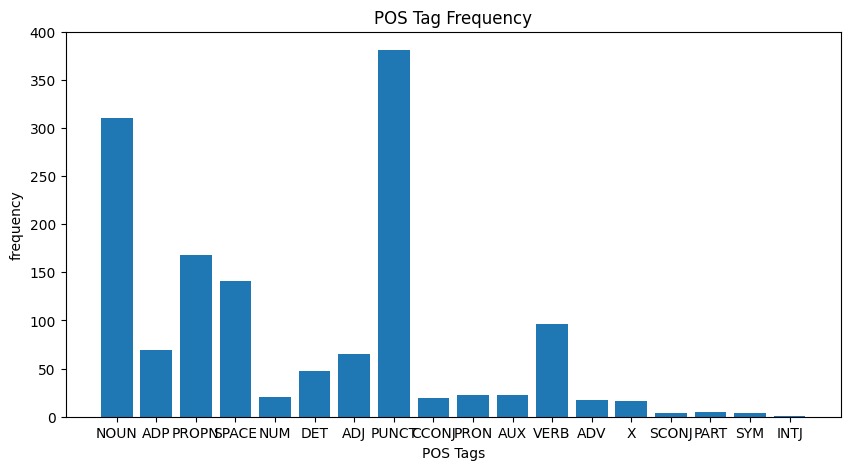

In [40]:
# (b) Plot the POS tag frequency as a bar chart
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.bar(pos_counts.keys(),
        pos_counts.values())

plt.xlabel('POS Tags')
plt.ylabel('frequency')
plt.title('POS Tag Frequency')

plt.show()

In [41]:
# (c) Render the dependency (grammar) tree with displacy
from spacy import displacy

displacy.render(doc[1307:1315],style='dep',jupyter=True)

In [43]:
# (d) Store the word, POS and meaning in a DataFrame
import pandas as pd

data=[]
for token in doc[192:214]:
  data.append({'Word':token.text,'POS':token.pos_,'Meaning':spacy.explain(token.pos_)})

df=pd.DataFrame(data)
print(df)

         Word    POS      Meaning
0       Self   NOUN         noun
1           -   NOUN         noun
2   attention   NOUN         noun
3           :  PUNCT  punctuation
4       every    DET   determiner
5       token    ADJ    adjective
6    compares   VERB         verb
7      itself   PRON      pronoun
8        with    ADP   adposition
9       every    DET   determiner
10      other    ADJ    adjective
11      token   VERB         verb
12         to   PART     particle
13     decide   VERB         verb
14      which    DET   determiner
15       ones   NOUN         noun
16     matter   VERB         verb
17        for    ADP   adposition
18        its   PRON      pronoun
19         \n  SPACE        space
20    meaning   NOUN         noun
21          .  PUNCT  punctuation


## Question 9: POS Tagging with NLTK
**(a)** Download the NLTK resources, split the PDF text into sentences and tag nltk sentence 3.
**(b)** Print each word of nltk sentence 3 with its tag as `word -> tag`.
**(c)** Print the nouns (`NN`) of nltk sentence 8.
**(d)** Print the verbs (`VB`) of nltk sentence 9.
**(e)** Print the adjectives (`JJ`) of nltk sentence 3.
**(f)** Print the adverbs (`RB`) of nltk sentence 3.
**(g)** Tag nltk sentences 7 to 9 using a loop.
**(h)** Count the POS tags of nltk sentence 10.

In [44]:
# (a) Download the NLTK resources, split the text into sentences and tag one sentence
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')

sentences=nltk.sent_tokenize(doc.text)

sentence=sentences[3]
words=nltk.word_tokenize(sentence)
pos_tags=nltk.pos_tag(words)
print(pos_tags)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


[('This', 'DT'), ('makes', 'VBZ'), ('training', 'NN'), ('far', 'RB'), ('faster', 'RBR'), ('on', 'IN'), ('modern', 'JJ'), ('hardware', 'NN'), ('and', 'CC'), ('lets', 'VBZ'), ('the', 'DT'), ('model', 'NN'), ('capture', 'NN'), ('long-range', 'JJ'), ('dependencies', 'NNS'), ('between', 'IN'), ('words', 'NNS'), ('.', '.')]


In [45]:
# (b) POS tagging of a simple sentence, one word per line
sentence=sentences[3]
words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)
for word,tag in tags:
  print(word,'->',tag)

This -> DT
makes -> VBZ
training -> NN
far -> RB
faster -> RBR
on -> IN
modern -> JJ
hardware -> NN
and -> CC
lets -> VBZ
the -> DT
model -> NN
capture -> NN
long-range -> JJ
dependencies -> NNS
between -> IN
words -> NNS
. -> .


In [46]:
# (c) Identifying nouns
sentence=sentences[8]
words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)

for word,tag in tags:
  if tag.startswith('NN'):
    print(word)

Self-attention
token
token
ones
matter
meaning


In [47]:
# (d) Identifying verbs
sentence=sentences[9]
words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)

for word,tag in tags:
  if tag.startswith('VB'):
    print(word,'->',tag)

run -> VBP
learning -> VBG


In [48]:
# (e) Identifying adjectives
sentence=sentences[3]
words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)

for word,tag in tags:
  if tag.startswith('JJ'):
    print(word,'->',tag)

modern -> JJ
long-range -> JJ


In [49]:
# (f) Identifying adverbs
sentence=sentences[3]
words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)

for word,tag in tags:
  if tag.startswith('RB'):
    print(word,'->',tag)

far -> RB
faster -> RBR


In [50]:
# (g) POS Tagging with multiple sentences
for sentence in sentences[7:10]:
  words=nltk.word_tokenize(sentence)
  tags=nltk.pos_tag(words)

  print('\nSentence:',sentence)
  print(tags)


Sentence: Positional encoding: since attention has no sense of order, position information is added to the
embeddings.
[('\x7fPositional', 'JJ'), ('encoding', 'NN'), (':', ':'), ('since', 'IN'), ('attention', 'NN'), ('has', 'VBZ'), ('no', 'DT'), ('sense', 'NN'), ('of', 'IN'), ('order', 'NN'), (',', ','), ('position', 'NN'), ('information', 'NN'), ('is', 'VBZ'), ('added', 'VBN'), ('to', 'TO'), ('the', 'DT'), ('embeddings', 'NNS'), ('.', '.')]

Sentence: Self-attention: every token compares itself with every other token to decide which ones matter for its
meaning.
[('\x7fSelf-attention', 'NN'), (':', ':'), ('every', 'DT'), ('token', 'NN'), ('compares', 'VBZ'), ('itself', 'PRP'), ('with', 'IN'), ('every', 'DT'), ('other', 'JJ'), ('token', 'NN'), ('to', 'TO'), ('decide', 'VB'), ('which', 'WDT'), ('ones', 'NNS'), ('matter', 'NN'), ('for', 'IN'), ('its', 'PRP$'), ('meaning', 'NN'), ('.', '.')]

Sentence: Multi-head attention: several attention heads run in parallel, each learning a diffe

In [51]:
# (h) Count POS tags
from collections import Counter

sentence=sentences[10]

words=nltk.word_tokenize(sentence)
tags=nltk.pos_tag(words)

pos_count=Counter(tag for word,tag in tags)

print(pos_count)

Counter({'NN': 6, 'JJ': 2, ',': 2, 'IN': 2, 'NNS': 1, 'NNP': 1, ':': 1, 'VBN': 1, 'DT': 1, 'TO': 1, 'VB': 1, 'CC': 1, '.': 1})


## Question 10: Named Entity Recognition with spaCy
**(a)** Print the entities and labels found in `doc[37:87]` (the sentence with *Vaswani* and *2017*).
**(b)** Extract only the `PERSON` entities of the whole PDF.
**(c)** Extract only the `ORG` entities of the whole PDF.
**(d)** Print the entities of `doc[108:138]` with the meaning of each label.
**(e)** Highlight the entities of `doc[37:87]` using displaCy.
**(f)** Count the entity labels of the whole PDF and show them as a bar chart.
**(g)** Create a DataFrame of the entities of `doc[37:138]`.



In [52]:
# (a) doc.ents contains the named entities found by spaCy
for ent in doc[37:87].ents:
  print(ent.text,ent.label_)

Transformer ORG
Attention GPE
2017 DATE


In [53]:
# (b) Extract only person entities
for ent in doc.ents:
  if ent.label_ == 'PERSON':
    print(ent.text)

Claude
subword tokens
Bidirectional
model="bert-base
= SentenceTransformer("all-MiniLM-L6-v2


In [54]:
# (c) Extract Organizations
for ent in doc.ents:
  if ent.label_ == 'ORG':
    print(ent.text)

NLP
Page 1
 
NLP
 
NLP
Transformer
Transformer
NLP
BERT
GPT
Core Components
BPE
WordPiece
LayerNorm
Query
Key (K
Transformer
BERT
NER
QA
T5
BART
mT5
NLP
API
NER
Google
Transformer
GPU
SentenceTransformer
NLP
IMDB
AutoTokenizer
TrainingArguments
Trainer
NLP
BERT
GPU
CPU
BERT


In [55]:
# (d) Extract all entity types with the meaning of the label
for ent in doc[108:138].ents:
  print('Entity:',ent.text,
        '|Label:',ent.label_,
        '|Meaning:',spacy.explain(ent.label_))

Entity: NLP |Label: ORG |Meaning: Companies, agencies, institutions, etc.
Entity: today |Label: DATE |Meaning: Absolute or relative dates or periods
Entity: BERT |Label: ORG |Meaning: Companies, agencies, institutions, etc.
Entity: GPT |Label: ORG |Meaning: Companies, agencies, institutions, etc.
Entity: T5 |Label: GPE |Meaning: Countries, cities, states
Entity: LLaMA |Label: DATE |Meaning: Absolute or relative dates or periods
Entity: Claude |Label: PERSON |Meaning: People, including fictional


In [56]:
# (e) NER Visualization with displacy
from spacy import displacy

displacy.render(doc[37:87],style='ent',jupyter=True)

Counter({'ORG': 39, 'CARDINAL': 18, 'DATE': 7, 'GPE': 6, 'PERSON': 5, 'WORK_OF_ART': 3, 'NORP': 2, 'PRODUCT': 1})


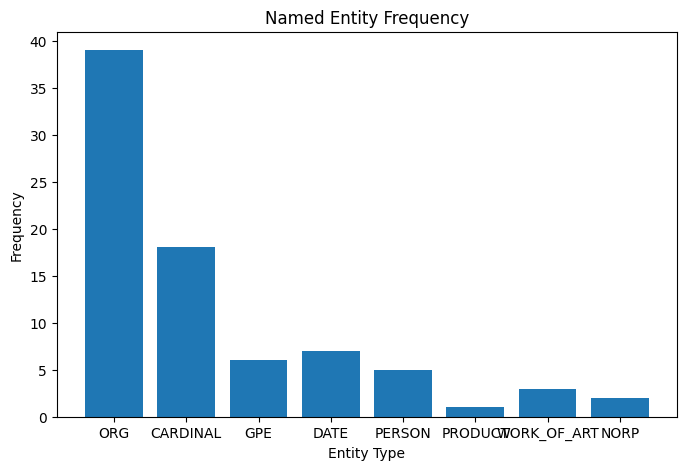

In [57]:
# (f) Count each entity type and plot it
from collections import Counter
import matplotlib.pyplot as plt

entity_counts=Counter(ent.label_ for ent in doc.ents)
print(entity_counts)
plt.figure(figsize=(8,5))
plt.bar(entity_counts.keys(),
        entity_counts.values()
        )

plt.xlabel('Entity Type')
plt.ylabel('Frequency')
plt.title('Named Entity Frequency')

plt.show()

In [58]:
# (g) Create an NER DataFrame
import pandas as pd

data=[]
for ent in doc[37:138].ents:
  data.append({'Entity':ent.text,
               'Label:':ent.label_,
               'Description':spacy.explain(ent.label_)
               })
df=pd.DataFrame(data)
print(df)

        Entity  Label:                              Description
0  Transformer     ORG  Companies, agencies, institutions, etc.
1    Attention     GPE                Countries, cities, states
2         2017    DATE    Absolute or relative dates or periods
3          NLP     ORG  Companies, agencies, institutions, etc.
4        today    DATE    Absolute or relative dates or periods
5         BERT     ORG  Companies, agencies, institutions, etc.
6          GPT     ORG  Companies, agencies, institutions, etc.
7           T5     GPE                Countries, cities, states
8        LLaMA    DATE    Absolute or relative dates or periods
9       Claude  PERSON              People, including fictional


## Question 11: Named Entity Recognition with NLTK
**(a)** Download the NER resources and print the `ne_chunk` tree of nltk sentence 4.
**(b)** Extract the `PERSON` entities of nltk sentence 2.
**(c)** Extract the `ORGANIZATION` entities of nltk sentence 4.
**(d)** Extract the `GPE` entities of nltk sentence 4.
**(e)** Create a function `extract_entities` and test it on nltk sentence 2.

In [59]:
# (a) Basic NER: tokenize, POS-tag and chunk the sentence, then print the tree
nltk.download('maxent_ne_chunker')
nltk.download('maxent_ne_chunker_tab')
nltk.download('words')

sentence=sentences[4]
words=nltk.word_tokenize(sentence)
pos_tags=nltk.pos_tag(words)

tree=nltk.ne_chunk(pos_tags)
print(tree)

[nltk_data] Downloading package maxent_ne_chunker to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker.zip.
[nltk_data] Downloading package maxent_ne_chunker_tab to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping chunkers/maxent_ne_chunker_tab.zip.
[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.


(S
  Almost/RB
  every/DT
  state-of-the-art/JJ
  (ORGANIZATION NLP/NNP)
  system/NN
  today/NN
  (/(
  (ORGANIZATION BERT/NNP)
  ,/,
  (ORGANIZATION GPT/NNP)
  ,/,
  (GPE T5/NNP)
  ,/,
  (ORGANIZATION LLaMA/NNP)
  ,/,
  (GPE Claude/NNP)
  )/)
  is/VBZ
  built/VBN
  on/IN
  this/DT
  idea/NN
  ./.)


In [60]:
# (b) Extract Person Names
sentence=sentences[2]
words=nltk.word_tokenize(sentence)
pos_tags=nltk.pos_tag(words)

tree=nltk.ne_chunk(pos_tags)
for chunk in tree:
  if hasattr(chunk,'label'):
    if chunk.label()=='PERSON':
      print('Person:',' '.join(c[0] for c in chunk))

Person: Vaswani


In [61]:
# (c) Extract Organizations
sentence=sentences[4]

words=nltk.word_tokenize(sentence)
pos_tags=nltk.pos_tag(words)

tree=nltk.ne_chunk(pos_tags)
for chunk in tree:
  if hasattr(chunk,'label'):
    if chunk.label()=='ORGANIZATION':
      print('Organization:',' '.join(c[0] for c in chunk))

Organization: NLP
Organization: BERT
Organization: GPT
Organization: LLaMA


In [62]:
# (d) Extract GPE (geo-political) entities
for chunk in tree:
  if hasattr(chunk,'label'):
    if chunk.label()=='GPE':
      print('GPE:',' '.join(c[0] for c in chunk))

GPE: T5
GPE: Claude


In [63]:
# (e) Create a function for NER
def extract_entities(sentence):
  words=nltk.word_tokenize(sentence)
  pos_tags=nltk.pos_tag(words)
  tree=nltk.ne_chunk(pos_tags)

  entities=[]

  for chunk in tree:
    if hasattr(chunk,'label'):
      entity=' '.join(word for word,tag in chunk)
      entities.append((entity,chunk.label()))

  return entities

sentence=sentences[2]
print(extract_entities(sentence))

[('Transformer', 'ORGANIZATION'), ('Vaswani', 'PERSON'), ('RNNs', 'ORGANIZATION'), ('LSTMs', 'ORGANIZATION')]


## Question 12: Vocabulary and Matching
**(a)** Create a `Matcher` with three patterns for **self-attention** (`selfattention`, `self attention`, `self-attention`).
**(b)** Apply the matcher on the PDF `doc` and print the matches.
**(c)** Print the match id, string id, start, end and text of each match.
**(d)** Create a `PhraseMatcher` for the phrases *self-attention*, *pretrained model*, *pretrained models*, *text classification*, *encoder-decoder*, *fine-tuning* and *test set*.
**(e)** Apply the phrase matcher on the `doc` and print the matches.
**(f)** Look at the text around three matches using the token indexes: `doc[60:90]`, `doc[545:565]` and `doc[1320:1335]`.

In [64]:
# (a) Define the token patterns and add them to a Matcher
from spacy.matcher import Matcher
matcher=Matcher(nlp.vocab)

pattern1=[{'LOWER':'selfattention'}]
pattern2=[{'LOWER':'self'},{'LOWER':'attention'}]
pattern3=[{'LOWER':'self'},{'IS_PUNCT':True},{'LOWER':'attention'}]
matcher.add('SelfAttention',[pattern1,pattern2,pattern3])

In [65]:
# (b) Run the matcher on the PDF document; each match is (match_id, start, end)
found_matches=matcher(doc)
print(found_matches)

[(4458165471169834419, 68, 71)]


In [66]:
# (c) Print the details of every match
for match_id,start,end in found_matches:
  string_id=nlp.vocab.strings[match_id]
  span=doc[start:end]
  print(match_id,string_id,start,end,span.text)

4458165471169834419 SelfAttention 68 71 self-attention


In [67]:
# (d) Create a PhraseMatcher, a phrase list and the phrase patterns, then add them
from spacy.matcher import PhraseMatcher
matcher=PhraseMatcher(nlp.vocab)

phrase_list=['self-attention','pretrained model','pretrained models','text classification','encoder-decoder','fine-tuning','test set']

phrase_patterns=[nlp(text) for text in phrase_list]

matcher.add('TransformerTerms',phrase_patterns)

In [68]:
# (e) Run the phrase matcher on the doc and print the matches
matches=matcher(doc)
print(matches)

[(6207857357844919380, 68, 71), (6207857357844919380, 548, 550), (6207857357844919380, 601, 603), (6207857357844919380, 611, 613), (6207857357844919380, 1023, 1025), (6207857357844919380, 1046, 1048), (6207857357844919380, 1244, 1247), (6207857357844919380, 1299, 1302), (6207857357844919380, 1324, 1326), (6207857357844919380, 1343, 1345)]


In [69]:
# (f) Print the text around some matches using the token indexes
print(doc[60:90])
print()
print(doc[545:565])
print()
print(doc[1320:1335])

that
processes entire sequences in parallel using self-attention instead of the step-by-step recurrence used by
RNNs and LSTMs. This makes training

to thousands of pretrained models.
pip install transformers datasets torch scikit-learn evaluate accelerate
5.

a held-out test set and report F1 or accuracy, not just training
